 # AI-Based Prescriptive Digital Twin for Green Hydrogen Production Optimization



 ## Notebook 03: Fuel Cell Dataset

In [226]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from pathlib import Path
import joblib
import shap

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

from sklearn.model_selection import (
    cross_val_score,
    StratifiedKFold
)

# Load Dataset

In [227]:
DATA_PATH = Path("../03_Dataset/01_Standardized/fuel_cell_standardized.csv")

df = pd.read_csv(DATA_PATH)

df.head()


,test_id,test_type,time_min,voltage_v,temperature_c,pressure_bar,hydrogen_flow_l_min,outcome,duration_min
0,Legacy_000,Before_AI,0,48.248357,69.792604,3.076151,15.194307,Fail,180
1,Legacy_000,Before_AI,1,47.838479,69.715461,3.038372,15.490431,Fail,180
2,Legacy_000,Before_AI,2,47.676374,70.947173,2.976714,14.894308,Fail,180
3,Legacy_000,Before_AI,3,47.987648,67.330080,2.971886,14.532525,Fail,180
4,Legacy_000,Before_AI,4,47.315807,70.738038,2.929385,14.794259,Fail,180


In [228]:
df.sample(5)


,test_id,test_type,time_min,voltage_v,temperature_c,pressure_bar,hydrogen_flow_l_min,outcome,duration_min
5298,Legacy_029,Before_AI,78,47.562639,72.465887,2.928441,15.107694,Pass,180
17114,Legacy_095,Before_AI,14,47.493210,69.300300,2.976905,15.271262,Pass,180
22180,AI_046,After_AI,70,46.892608,69.718882,2.980530,15.299113,Pass,91
21469,AI_038,After_AI,77,47.267358,70.175559,2.995933,15.384886,Pass,88
6650,Legacy_036,Before_AI,170,46.121222,73.773733,3.011427,14.801731,Pass,180


# Data Preprocessing

## Initial verification

 ### Dataset Information

In [229]:
rows, cols = df.shape

print(f"Number of Samples : {rows}")
print(f"Number of Features: {cols}")


Number of Samples : 26930
Number of Features: 9


In [230]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26930 entries, 0 to 26929
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   test_id              26930 non-null  object 
 1   test_type            26930 non-null  object 
 2   time_min             26930 non-null  int64  
 3   voltage_v            26930 non-null  float64
 4   temperature_c        26930 non-null  float64
 5   pressure_bar         26930 non-null  float64
 6   hydrogen_flow_l_min  26930 non-null  float64
 7   outcome              26930 non-null  object 
 8   duration_min         26930 non-null  int64  
dtypes: float64(4), int64(2), object(3)
memory usage: 1.8+ MB


In [231]:
df.columns.tolist()


['test_id',
 'test_type',
 'time_min',
 'voltage_v',
 'temperature_c',
 'pressure_bar',
 'hydrogen_flow_l_min',
 'outcome',
 'duration_min']

In [232]:
pd.DataFrame({
    "Column": df.columns,
    "Type": df.dtypes.values
})


,Column,Type
0,test_id,object
1,test_type,object
2,time_min,int64
3,voltage_v,float64
4,temperature_c,float64
5,pressure_bar,float64
6,hydrogen_flow_l_min,float64
7,outcome,object
8,duration_min,int64


In [233]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
test_id,26930,200,Legacy_000,180,NaN,NaN,NaN,NaN,NaN,NaN,NaN
test_type,26930,2,Before_AI,18000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
time_min,26930.0,NaN,NaN,NaN,74.46736,49.810002,0.0,33.0,67.0,112.0,179.0
voltage_v,26930.0,NaN,NaN,NaN,46.428384,1.769222,38.411369,46.136399,46.981294,47.53353,49.583453
temperature_c,26930.0,NaN,NaN,NaN,72.353625,2.834687,66.117729,70.564629,71.645678,73.120493,85.170991
pressure_bar,26930.0,NaN,NaN,NaN,2.999894,0.049929,2.792113,2.965918,3.000225,3.033549,3.223954
hydrogen_flow_l_min,26930.0,NaN,NaN,NaN,15.371983,0.76764,14.076107,14.915017,15.093284,15.433135,18.717197
outcome,26930,2,Pass,18860,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration_min,26930.0,NaN,NaN,NaN,149.93472,42.697135,85.0,90.0,180.0,180.0,180.0


## Missing Values

In [234]:
round(df.isnull().sum().sort_values(ascending=False)*100/len(df), 2)

test_id                0.0
test_type              0.0
time_min               0.0
voltage_v              0.0
temperature_c          0.0
pressure_bar           0.0
hydrogen_flow_l_min    0.0
outcome                0.0
duration_min           0.0
dtype: float64

## Duplicate Rows

In [235]:
df.duplicated().sum()

np.int64(0)

## Outliers Detection

In [236]:
num_cols = df.select_dtypes(include="number").columns

In [237]:
for col in num_cols:

    fig = px.box(
        df,
        y=col,
        title=f"Outliers - {col}"
    )

    fig.show()


In [238]:
outliers_dict = {}

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    
    outliers_dict[col] = len(outliers)

print(outliers_dict)

{'time_min': 0, 'voltage_v': 2838, 'temperature_c': 2369, 'pressure_bar': 184, 'hydrogen_flow_l_min': 3737, 'duration_min': 0}


In [239]:
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower, upper)

In [240]:
for col in num_cols:

    fig = px.box(
        df,
        y=col,
        title=f"Outliers - {col}"
    )

    fig.show()


## Target Investigation

In [241]:
TARGET = "outcome"

In [242]:
df[TARGET].unique()

array(['Fail', 'Pass'], dtype=object)

In [243]:
df[TARGET].value_counts()

outcome
Pass    18860
Fail     8070
Name: count, dtype: int64

In [244]:
px.histogram(
    df,
    x=TARGET,
    color=TARGET,
    title="Outcome Distribution"
)


# Data Analysis and Visualization

 ## Feature Categories



 | Feature | Category |
 |---------|----------|
 | test_id | Test Identifier |
 | test_type | Test Type |
 | time_min      | Time |
 | voltage_v     | Electrical |
 | temperature_c | Thermal    |
 | pressure_kpa  | Process |
 | h2_flow_lpm   | Hydrogen Flow |
 | duration_min  | Test Duration |
 | outcome       | Target |

 ## Numerical Feature Distributions

In [245]:
for col in num_cols.drop(["time_min","duration_min"]):

    fig = px.histogram(
        df,
        x=col,
        title=f"Distribution of {col}"
    )

    fig.show()


 ## Categorical Feature Distributions

In [246]:
categorical_cols = df.select_dtypes(include="object").columns

categorical_cols


Index(['test_id', 'test_type', 'outcome'], dtype='object')

In [247]:
for col in categorical_cols:

    fig = px.histogram(
        df,
        x=col,
        color=col,
        title=f"{col} Distribution"
    )

    fig.show()


 ## Operational Analysis

In [248]:
px.scatter(
    df,
    x="time_min",
    y="voltage_v",
    color="test_type",
    title="Voltage vs Time"
)


In [249]:
px.scatter(
    df,
    x="time_min",
    y="temperature_c",
    color="test_type",
    title="Temperature vs Time"
)


In [250]:
px.scatter(
    df,
    x="time_min",
    y="pressure_bar",
    color="test_type",
    title="Pressure vs Time"
)


In [251]:
px.scatter(
    df,
    x="time_min",
    y="hydrogen_flow_l_min",
    color="test_type",
    title="Hydrogen Flow vs Time"
)


 ## Correlation Matrix

In [252]:
corr = df.corr(numeric_only=True)

corr


,time_min,voltage_v,temperature_c,pressure_bar,hydrogen_flow_l_min,duration_min
time_min,1.000000,-0.605922,0.542242,-0.001077,0.206901,0.428600
voltage_v,-0.605922,1.000000,-0.840276,-0.005221,-0.786183,-0.249731
temperature_c,0.542242,-0.840276,1.000000,0.000972,0.721068,0.233717
pressure_bar,-0.001077,-0.005221,0.000972,1.000000,0.000880,0.000695
hydrogen_flow_l_min,0.206901,-0.786183,0.721068,0.000880,1.000000,0.079244
duration_min,0.428600,-0.249731,0.233717,0.000695,0.079244,1.000000


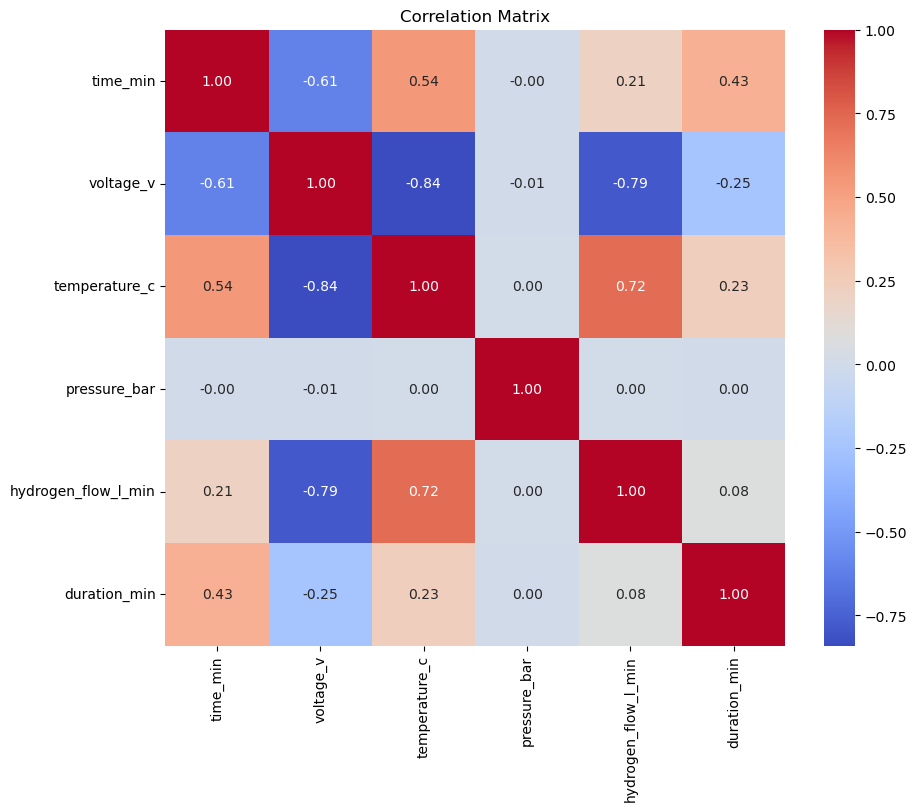

In [253]:
plt.figure(figsize=(10,8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()


## Test ID Investigation

In [254]:
df["test_id"].nunique()

200

In [255]:
df["test_id"].value_counts().head(10)

test_id
Legacy_000    180
Legacy_064    180
Legacy_075    180
Legacy_074    180
Legacy_073    180
Legacy_072    180
Legacy_071    180
Legacy_069    180
Legacy_068    180
Legacy_067    180
Name: count, dtype: int64

In [256]:
df.groupby("test_id").size().describe()

count    200.000000
mean     134.650000
std       45.479992
min       85.000000
25%       90.000000
50%      136.500000
75%      180.000000
max      180.000000
dtype: float64

## Encode Target Variable

In [257]:
df[TARGET] = df[TARGET].map({
    "Fail":0,
    "Pass":1
})

df[TARGET].value_counts()


outcome
1    18860
0     8070
Name: count, dtype: int64

# Feature Selection

In [258]:
X = df.drop(columns=[TARGET])
X=X.drop(columns=["test_type","time_min","duration_min"])
y = df[TARGET]

print(X.shape)

X.head()


(26930, 5)


,test_id,voltage_v,temperature_c,pressure_bar,hydrogen_flow_l_min
0,Legacy_000,48.248357,69.792604,3.076151,15.194307
1,Legacy_000,47.838479,69.715461,3.038372,15.490431
2,Legacy_000,47.676374,70.947173,2.976714,14.894308
3,Legacy_000,47.987648,67.330080,2.971886,14.532525
4,Legacy_000,47.315807,70.738038,2.929385,14.794259


# Train-Test Split

In [259]:
groups = df["test_id"]

splitter = GroupShuffleSplit(
    test_size=0.20,
    random_state=42,
    n_splits=1
)

train_idx, test_idx = next(
    splitter.split(X, y, groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

In [260]:
X_train = X_train.drop(columns=["test_id"])

X_test = X_test.drop(columns=["test_id"])

In [261]:
print("Training Target Distribution")

print(y_train.value_counts(normalize=True))

print()

print("Testing Target Distribution")

print(y_test.value_counts(normalize=True))

Training Target Distribution
outcome
1    0.680887
0    0.319113
Name: proportion, dtype: float64

Testing Target Distribution
outcome
1    0.779792
0    0.220208
Name: proportion, dtype: float64


# Feature Scaling

In [262]:
numeric_features = X_train.select_dtypes(include=np.number).columns

scaler = StandardScaler()

X_train_scaled = X_train.copy()

X_test_scaled = X_test.copy()

X_train_scaled[numeric_features] = scaler.fit_transform(
    X_train[numeric_features]
)

X_test_scaled[numeric_features] = scaler.transform(
    X_test[numeric_features]
)

X_train_scaled.head()


,voltage_v,temperature_c,pressure_bar,hydrogen_flow_l_min
0,1.319157,-1.061628,1.536303,-0.159413
1,0.990751,-1.095883,0.775518,0.432891
2,0.860869,-0.548944,-0.466117,-0.759466
3,1.110269,-2.155107,-0.563338,-1.483101
4,0.571973,-0.641810,-1.419192,-0.959582


In [263]:
print("Training Dataset Shape :", X_train_scaled.shape)

print("Testing Dataset Shape  :", X_test_scaled.shape)

print()

print("Remaining Missing Values")

print(X_train_scaled.isnull().sum().sum())


Training Dataset Shape : (21635, 4)
Testing Dataset Shape  : (5295, 4)

Remaining Missing Values
0


In [264]:
print(f"Training Samples : {len(X_train_scaled)}")
print(f"Testing Samples  : {len(X_test_scaled)}")

print()

print("Number of Features :", X_train_scaled.shape[1])


Training Samples : 21635
Testing Samples  : 5295

Number of Features : 4


# Correlation Analysis

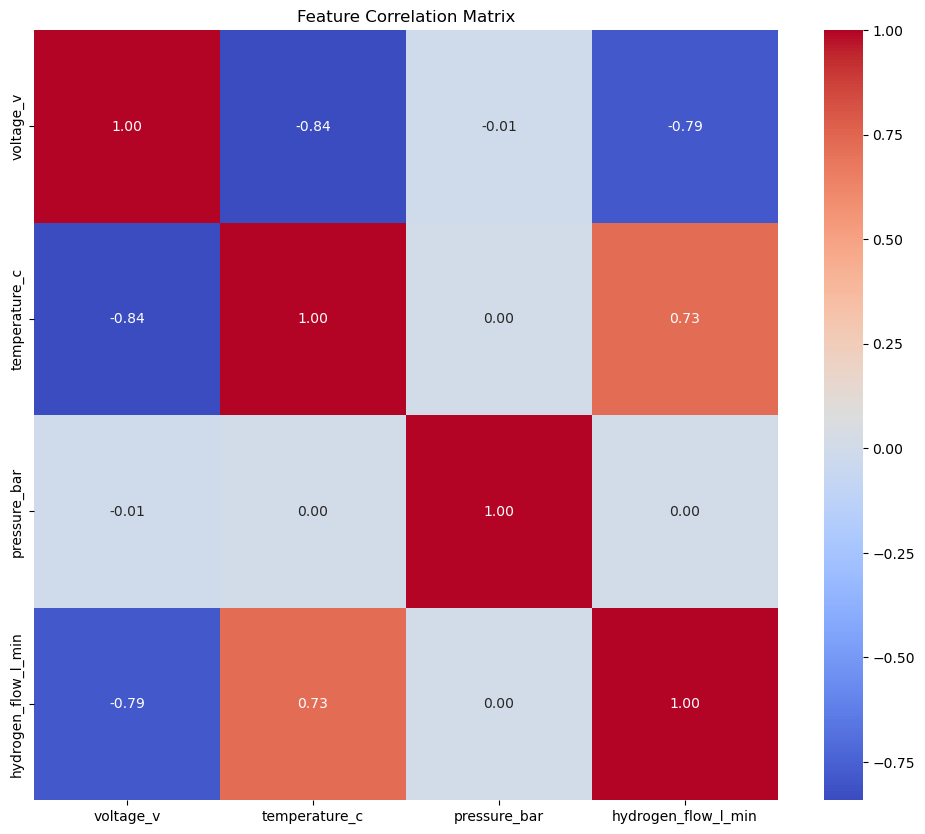

In [265]:
corr = X_train_scaled.corr()

plt.figure(figsize=(12,10))

sns.heatmap(
    corr,
    cmap="coolwarm",
    annot=True,
    fmt=".2f"
)

plt.title("Feature Correlation Matrix")

plt.show()


 ## Mutual Information

In [266]:
mi_scores = mutual_info_classif(
    X_train_scaled,
    y_train,
    random_state=42
)

mi_scores = pd.Series(
    mi_scores,
    index=X_train_scaled.columns
).sort_values(ascending=False)

mi_scores


hydrogen_flow_l_min    0.401414
voltage_v              0.280299
temperature_c          0.242210
pressure_bar           0.000000
dtype: float64

In [267]:
px.bar(
    mi_scores,
    title="Mutual Information Scores"
)


## Random Forest Feature Importance

In [268]:
rf = RandomForestClassifier(
    random_state=42
)

rf.fit(X_train_scaled, y_train)

importance = pd.Series(
    rf.feature_importances_,
    index=X_train_scaled.columns
).sort_values(ascending=False)

importance


hydrogen_flow_l_min    0.498681
voltage_v              0.293153
temperature_c          0.145786
pressure_bar           0.062381
dtype: float64

In [269]:
px.bar(
    importance,
    title="Random Forest Feature Importance"
)


# Final Feature Selection

In [270]:
selected_features = importance[
    importance > 0.01
].index.tolist()

selected_features


['hydrogen_flow_l_min', 'voltage_v', 'temperature_c', 'pressure_bar']

In [271]:
X_train_final = X_train_scaled[selected_features]

X_test_final = X_test_scaled[selected_features]

X_train_final.head()


,hydrogen_flow_l_min,voltage_v,temperature_c,pressure_bar
0,-0.159413,1.319157,-1.061628,1.536303
1,0.432891,0.990751,-1.095883,0.775518
2,-0.759466,0.860869,-0.548944,-0.466117
3,-1.483101,1.110269,-2.155107,-0.563338
4,-0.959582,0.571973,-0.641810,-1.419192


In [272]:
print("Training Shape :", X_train_final.shape)
print("Testing Shape  :", X_test_final.shape)

Training Shape : (21635, 4)
Testing Shape  : (5295, 4)


In [273]:
print("Training Target Shape :", y_train.shape)
print("Testing Target Shape  :", y_test.shape)

Training Target Shape : (21635,)
Testing Target Shape  : (5295,)


In [274]:
X_train_final.head()

,hydrogen_flow_l_min,voltage_v,temperature_c,pressure_bar
0,-0.159413,1.319157,-1.061628,1.536303
1,0.432891,0.990751,-1.095883,0.775518
2,-0.759466,0.860869,-0.548944,-0.466117
3,-1.483101,1.110269,-2.155107,-0.563338
4,-0.959582,0.571973,-0.641810,-1.419192


In [275]:
y_train.value_counts()

outcome
1    14731
0     6904
Name: count, dtype: int64

In [276]:
y_train.value_counts(normalize=True).mul(100).round(2)

outcome
1    68.09
0    31.91
Name: proportion, dtype: float64

In [277]:
y_test.value_counts()

outcome
1    4129
0    1166
Name: count, dtype: int64

In [278]:
y_test.value_counts(normalize=True).mul(100).round(2)

outcome
1    77.98
0    22.02
Name: proportion, dtype: float64

# Build Machine Learning Models

In [279]:

models = {

    "Logistic Regression":
        LogisticRegression(
            random_state=42,
            max_iter=1000
        ),

    "Decision Tree":
        DecisionTreeClassifier(
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            random_state=42,
            n_estimators=300,
            n_jobs=-1
        ),

    "XGBoost":
        XGBClassifier(
            subsample = 0.7,
            reg_lambda = 0.1,
            reg_alpha = 1e-05,
            n_estimators = 500,
            min_child_weight = 7,
            max_depth = 5,
            learning_rate = 0.1,
            gamma = 5,
            colsample_bytree = 0.9
        ),

    "LightGBM":
        LGBMClassifier(
            random_state=42,
            n_estimators=300,
            learning_rate=0.05
        ),

    "CatBoost":
        CatBoostClassifier(
            random_state=42,
            verbose=False
        )
}



## Train Models & Evaluate Performance

In [280]:

results = []

trained_models = {}


for name, model in models.items():
    model.fit(
        X_train_final,
        y_train
    )

    test_prediction = model.predict(
        X_test_final
    )

    accuracy = accuracy_score(
        y_test,
        test_prediction
    )

    balanced_accuracy = balanced_accuracy_score(
        y_test,
        test_prediction
    )

    precision = precision_score(
        y_test,
        test_prediction,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        test_prediction,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        test_prediction,
        zero_division=0
    )

    results.append({

        "Model": name,

        "Accuracy": accuracy,

        "Balanced Accuracy": balanced_accuracy,

        "Precision": precision,

        "Recall": recall,

        "F1 Score": f1
    })

    trained_models[name] = model



[LightGBM] [Info] Number of positive: 14731, number of negative: 6904
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000211 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1020
[LightGBM] [Info] Number of data points in the train set: 21635, number of used features: 4
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.680887 -> initscore=0.757853
[LightGBM] [Info] Start training from score 0.757853


## Model Comparison Results

In [281]:

results = pd.DataFrame(
    results
)

results = results.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(
    drop=True
)

results



,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score
0,XGBoost,0.949386,0.898002,0.947600,0.989828,0.968254
1,Logistic Regression,0.947309,0.893592,0.945396,0.989586,0.966986
2,LightGBM,0.946176,0.896866,0.948019,0.984984,0.966148
3,CatBoost,0.946176,0.897789,0.948646,0.984258,0.966124
4,Random Forest,0.944476,0.897007,0.948748,0.981836,0.965008
5,Decision Tree,0.896506,0.873942,0.951121,0.914265,0.932329


In [282]:

fig_accuracy = px.bar(

    results,

    x="Model",

    y="Accuracy",

    color="Model",

    title="Classification Model Comparison - Accuracy"
)

fig_accuracy.show()



In [283]:

fig_balanced_accuracy = px.bar(

    results,

    x="Model",

    y="Balanced Accuracy",

    color="Model",

    title="Classification Model Comparison - Balanced Accuracy"
)

fig_balanced_accuracy.show()



In [284]:

fig_f1 = px.bar(

    results,

    x="Model",

    y="F1 Score",

    color="Model",

    title="Classification Model Comparison - F1 Score"
)

fig_f1.show()



In [285]:

metrics_long = results[
    [
        "Model",
        "Precision",
        "Recall"
    ]
].melt(

    id_vars="Model",

    var_name="Metric",

    value_name="Score"
)


fig_precision_recall = px.bar(

    metrics_long,

    x="Model",

    y="Score",

    color="Metric",

    barmode="group",

    title="Precision vs Recall Comparison"
)

fig_precision_recall.show()



## Select Best Model

In [286]:

best_model_name = results.iloc[0]["Model"]

print("Best Model :", best_model_name)

best_model = trained_models[
    best_model_name
]



Best Model : XGBoost


 ## Best Model Validation

In [287]:
train_prediction = best_model.predict(
    X_train_final
)

test_prediction = best_model.predict(
    X_test_final
)


train_accuracy = accuracy_score(
    y_train,
    train_prediction
)

test_accuracy = accuracy_score(
    y_test,
    test_prediction
)


train_f1 = f1_score(
    y_train,
    train_prediction,
    zero_division=0
)

test_f1 = f1_score(
    y_test,
    test_prediction,
    zero_division=0
)


train_balanced_accuracy = balanced_accuracy_score(
    y_train,
    train_prediction
)

test_balanced_accuracy = balanced_accuracy_score(
    y_test,
    test_prediction
)

print(f"Best Model : {best_model_name}")

print()

print(f"Train Accuracy          : {train_accuracy:.4f}")
print(f"Test Accuracy           : {test_accuracy:.4f}")

print()

print(f"Train Balanced Accuracy : {train_balanced_accuracy:.4f}")
print(f"Test Balanced Accuracy  : {test_balanced_accuracy:.4f}")

print()

print(f"Train F1                : {train_f1:.4f}")
print(f"Test F1                 : {test_f1:.4f}")



Best Model : XGBoost

Train Accuracy          : 0.9317
Test Accuracy           : 0.9494

Train Balanced Accuracy : 0.9001
Test Balanced Accuracy  : 0.8980

Train F1                : 0.9516
Test F1                 : 0.9683


### Cross Validation

In [288]:

cv = StratifiedKFold(

    n_splits=5,

    shuffle=True,

    random_state=42
)


cv_scores = cross_val_score(

    best_model,

    X_train_final,

    y_train,

    cv=cv,

    scoring="f1",

    n_jobs=-1
)

print("Cross Validation F1 Scores:")

print(cv_scores)

print()

print(
    f"Average CV F1 : {cv_scores.mean():.4f}"
)

print(
    f"Std CV F1     : {cv_scores.std():.4f}"
)



Cross Validation F1 Scores:
[0.94614503 0.94971335 0.94639074 0.95320681 0.95278689]

Average CV F1 : 0.9496
Std CV F1     : 0.0030


### Classification Report

In [289]:
print(
    classification_report(
        y_test,
        test_prediction,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.96      0.81      0.88      1166
           1       0.95      0.99      0.97      4129

    accuracy                           0.95      5295
   macro avg       0.95      0.90      0.92      5295
weighted avg       0.95      0.95      0.95      5295



### Confusion Matrix

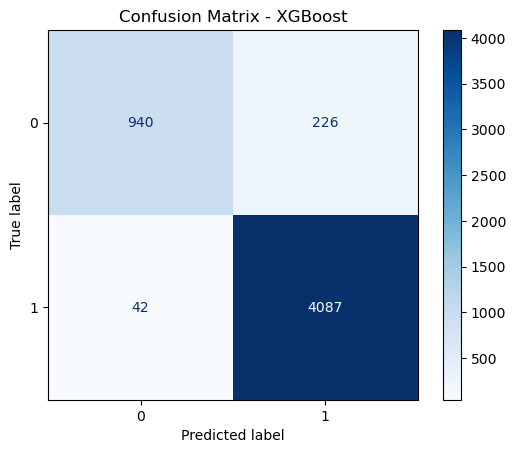

In [290]:

cm = confusion_matrix(

    y_test,

    test_prediction
)


disp = ConfusionMatrixDisplay(

    confusion_matrix=cm

)

disp.plot(
    cmap="Blues"
)

plt.title(
    f"Confusion Matrix - {best_model_name}"
)

plt.show()



### Validation Summary

In [291]:

train_test_gap = train_f1 - test_f1

cv_mean = cv_scores.mean()

test_cv_gap = abs(
    test_f1 - cv_mean
)

print(f"Train F1       : {train_f1:.4f}")
print(f"Test F1        : {test_f1:.4f}")
print(f"CV Mean F1     : {cv_mean:.4f}")

print()

print(
    f"Train-Test Gap : {train_test_gap:.4f}"
)

print(
    f"Test-CV Gap    : {test_cv_gap:.4f}"
)

print()


if train_test_gap < 0.05:

    print(
        "Model Generalization : Excellent"
    )

elif train_test_gap < 0.10:

    print(
        "Model Generalization : Good"
    )

else:

    print(
        "Potential Overfitting Detected"
    )


print()


if test_cv_gap < 0.05:

    print(
        "Test-CV Consistency : Excellent"
    )

elif test_cv_gap < 0.10:

    print(
        "Test-CV Consistency : Good"
    )

else:

    print(
        "Test-CV Difference : Requires Investigation"
    )



Train F1       : 0.9516
Test F1        : 0.9683
CV Mean F1     : 0.9496

Train-Test Gap : -0.0166
Test-CV Gap    : 0.0186

Model Generalization : Excellent

Test-CV Consistency : Excellent


## Final Model Performance Summary

In [292]:

final_summary = pd.DataFrame({

    "Metric": [

        "Accuracy",

        "Balanced Accuracy",

        "F1 Score",

        "CV Mean F1",

        "Train-Test F1 Gap",

        "Test-CV F1 Gap"
    ],

    "Value": [

        test_accuracy,

        test_balanced_accuracy,

        test_f1,

        cv_mean,

        train_test_gap,

        test_cv_gap
    ]
})


final_summary



,Metric,Value
0,Accuracy,0.949386
1,Balanced Accuracy,0.898002
2,F1 Score,0.968254
3,CV Mean F1,0.949649
4,Train-Test F1 Gap,-0.016605
5,Test-CV F1 Gap,0.018605


# Save Best Model

In [293]:

OUTPUT = Path(
    "00_Trained_Model/fuel_cell"
)

OUTPUT.mkdir(
    exist_ok=True
)


joblib.dump(

    best_model,

    OUTPUT / "best_fuel_cell_model.pkl"

)


print(
    "Best Fuel Cell model saved successfully."
)

print(
    OUTPUT / "best_fuel_cell_model.pkl"
)

joblib.dump(
    scaler,
    OUTPUT / "Fuel_Cell_scaler.pkl"
)

pd.DataFrame({"Feature": selected_features}).to_csv(
    OUTPUT / "Fuel_Cell_selected_features.csv",
    index=False
)

print("Fuel Cell scaler and selected features saved successfully.")



FileNotFoundError: [WinError 3] The system cannot find the path specified: '00_Trained_Model\\fuel_cell'

# Background Sample For SHAP

In [ ]:
background = X_train_scaled.sample(
    n=min(100, len(X_train_scaled)),
    random_state=42
)

print("Background shape:", background.shape)

Background shape: (100, 4)


# Explanation Sample for every test set

In [ ]:
X_explain = X_test_scaled

print("Explanation shape:", X_explain.shape)

Explanation shape: (5295, 4)


# Load Best Fit Model

In [ ]:
xgb_model = models["XGBoost"] 
joblib.dump(xgb_model, "xgboost.pkl") 

['xgboost.pkl']

# XGBoost TreeExplainer

In [ ]:
xgb_explainer = shap.TreeExplainer(
    xgb_model,
    feature_perturbation='tree_path_dependent'
)

# Calculate SHAP Values

In [299]:
xgb_shap_values = xgb_explainer(X_explain)

print("SHAP shape:", xgb_shap_values.values.shape)

SHAP shape: (5295, 4)


# Global Feature Importance

In [ ]:
xgb_importance = pd.DataFrame({
    "Feature": X_explain.columns,
    "Mean_Absolute_SHAP": np.abs(
        xgb_shap_values.values
    ).mean(axis=0)
})

xgb_importance = xgb_importance.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
)

xgb_importance

,Feature,Mean_Absolute_SHAP
0,voltage_v,2.582883
1,temperature_c,0.828062
2,pressure_bar,0.539400
3,hydrogen_flow_l_min,0.030160


# SHAP Bar Plot

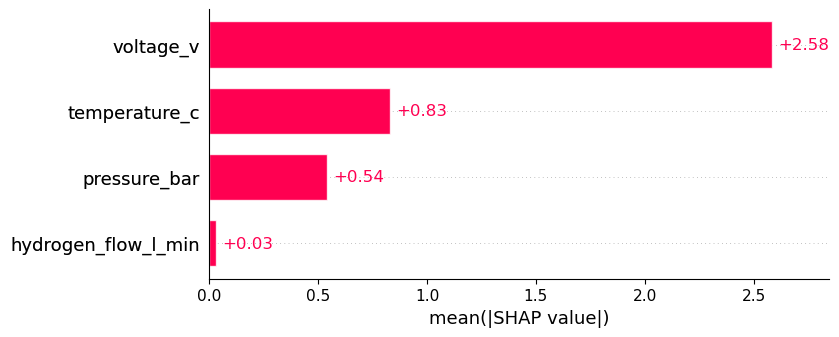

In [ ]:
shap.plots.bar(xgb_shap_values)

# SHAP Beeswarm

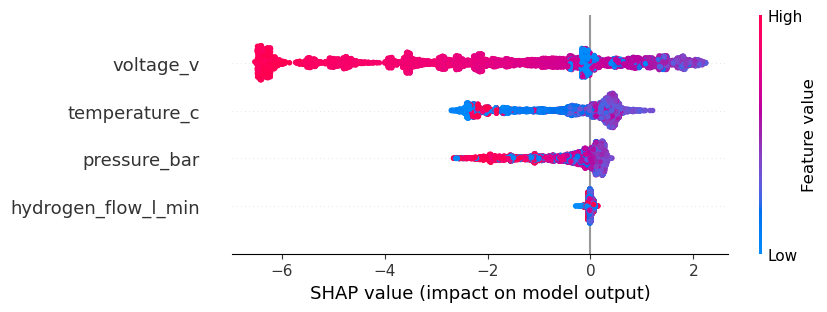

In [294]:
shap.plots.beeswarm(xgb_shap_values)

# Dependence Plot

Most important feature: voltage_v


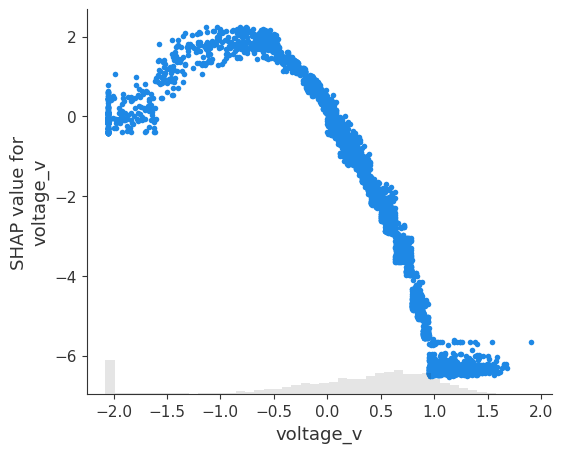

In [295]:
top_feature = xgb_importance.iloc[0]["Feature"]

print("Most important feature:", top_feature)

shap.plots.scatter(
    xgb_shap_values[:, top_feature]
)

# Local Explanation

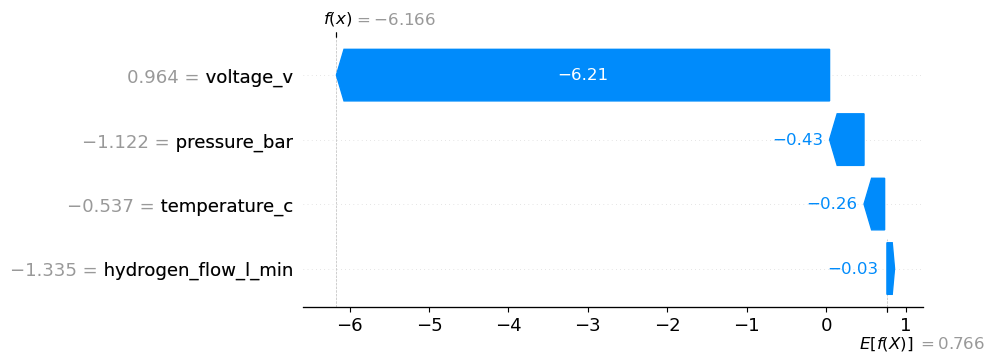

In [296]:
sample_index = 50
shap.plots.waterfall(
    xgb_shap_values[sample_index]
)

# Local Contribution Table

In [297]:
local_table = pd.DataFrame({
    "Feature": X_explain.columns,
    "Feature_Value": X_explain.iloc[sample_index].values,
    "SHAP_Value": xgb_shap_values.values[sample_index]
})

local_table["Absolute_SHAP"] = (
    local_table["SHAP_Value"].abs()
)

local_table["Effect"] = np.where(
    local_table["SHAP_Value"] > 0,
    "Pushes output higher",
    "Pushes output lower"
)

local_table = local_table.sort_values(
    by="Absolute_SHAP",
    ascending=False
)

local_table

,Feature,Feature_Value,SHAP_Value,Absolute_SHAP,Effect
0,voltage_v,0.963610,-6.209329,6.209329,Pushes output lower
2,pressure_bar,-1.122048,-0.433650,0.433650,Pushes output lower
1,temperature_c,-0.537168,-0.259325,0.259325,Pushes output lower
3,hydrogen_flow_l_min,-1.334964,-0.029263,0.029263,Pushes output lower


# +ve / -ve Effects

In [298]:
positive_effects = local_table[
    local_table["SHAP_Value"] > 0
]

negative_effects = local_table[
    local_table["SHAP_Value"] < 0
]

print("Positive effects:")
display(positive_effects)

print("\nNegative effects:")
display(negative_effects)

Positive effects:


,Feature,Feature_Value,SHAP_Value,Absolute_SHAP,Effect



Negative effects:


,Feature,Feature_Value,SHAP_Value,Absolute_SHAP,Effect
0,voltage_v,0.963610,-6.209329,6.209329,Pushes output lower
2,pressure_bar,-1.122048,-0.433650,0.433650,Pushes output lower
1,temperature_c,-0.537168,-0.259325,0.259325,Pushes output lower
3,hydrogen_flow_l_min,-1.334964,-0.029263,0.029263,Pushes output lower


# Save SHAP Values

In [302]:
xgb_model_shap_df = pd.DataFrame(
    xgb_shap_values.values,
    columns=X_explain.columns,
    index=X_explain.index
)


xgb_model_shap_df.to_csv("xgb_model_shap_values.csv")

# Save Global Importance

In [303]:
xgb_importance.to_csv(
    "xgboost_global_feature_importance.csv",
    index=False
)

# Save Local Contribution

In [306]:
local_table.to_csv(
    "xgboost_local_contribution.csv",
    index=False
)